# EcoHome Studio: application reference inventory

This analysis examines factual configuration values and a source-resource index from kasimsuh/ecohome-studio. It does not use a labelled material-recognition dataset. Source files are referenced rather than redistributed.

These are dataset analyses, not camera training results.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "datasets/dtd/source.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside a cloned Fitwell-AI repository")
plt.rcParams.update({"figure.facecolor": "#f5f1ea", "axes.facecolor": "#f5f1ea", "font.size": 11})
print("Repository:", ROOT.name)


Repository: repo


In [2]:
folder = ROOT / "datasets/ecohome-studio"
materials = pd.read_csv(folder / "material_options.csv")
resources = pd.read_csv(folder / "resource_inventory.csv")
climates = pd.read_csv(folder / "climate_options.csv")
budgets = pd.read_csv(folder / "budget_options.csv")
assert len(materials) == 10 and len(climates) == 5 and len(budgets) == 3
assert resources.path.is_unique
print(materials[["field", "value", "record_type"]].to_string(index=False))
print("\nSource resources:")
print(resources[["path", "resource_type", "size_bytes"]].to_string(index=False))

         field               value        record_type
facadeMaterial        timber-board application_option
facadeMaterial               brick application_option
facadeMaterial    rendered-plaster application_option
facadeMaterial        stone-veneer application_option
facadeMaterial         metal-panel application_option
facadeMaterial        fiber-cement application_option
  roofMaterial metal-standing-seam application_option
  roofMaterial           clay-tile application_option
  roofMaterial     asphalt-shingle application_option
  roofMaterial     rubber-membrane application_option

Source resources:
                                                                       path         resource_type  size_bytes
                                                    lib/domain/constants.ts application_reference        1826
                                        lib/domain/derive-report-metrics.ts application_reference        8155
                                          lib/domain/home

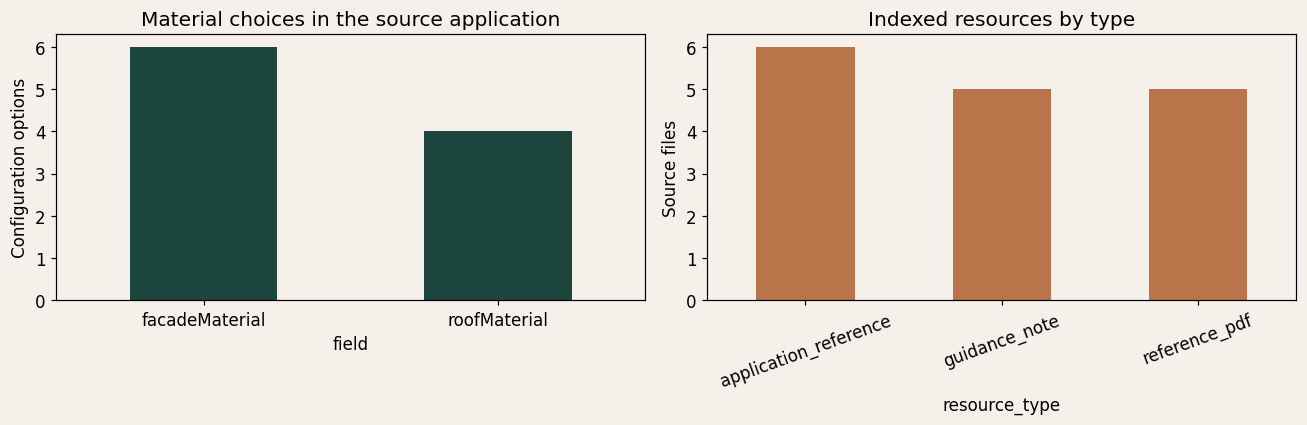

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
materials.groupby("field").size().plot.bar(ax=axes[0], color="#1c463d", rot=0)
axes[0].set_title("Material choices in the source application")
axes[0].set_ylabel("Configuration options")
resources.groupby("resource_type").size().plot.bar(ax=axes[1], color="#b97449", rot=20)
axes[1].set_title("Indexed resources by type")
axes[1].set_ylabel("Source files")
plt.tight_layout()
plt.show()

## Interpretation

The tables describe application configuration and referenced documents. They do not establish material performance, product availability, carbon impacts, or recognition accuracy. Demo records and scoring rules in the source application are not treated as empirical observations. No repository-wide licence was located at the indexed revision; source code and PDF contents have not been copied into Fitwell-AI. Their authorship and permissions remain with their respective owners. These resources have not been used to train the camera.